# PlantSeg × DINOv3 + LoRA: results analysis

Reproduces every table and figure of the README from the committed results (CPU only, no dataset, no GPU).
Run from the repository root's `notebooks/` folder. Requirements: `numpy`, `matplotlib`, `pandas`.

In [1]:
import json, pathlib, subprocess, sys
import numpy as np, pandas as pd
from IPython.display import Image, display
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
R = ROOT / "results"
def run(cmd):
    print(subprocess.run([sys.executable, *cmd], cwd=ROOT, capture_output=True, text=True, check=True).stdout[-2000:])

## 1. Per-run metrics
Each training run stores dev and test metrics in `results/{dev,test}/<run>.json`.

In [2]:
rows = []
for p in sorted((R / "dev").glob("*.json")):
    d, t = json.loads(p.read_text()), json.loads((R / "test" / p.name).read_text())
    rows.append({"run": d["id"], "model": d["label"], "dev mIoU": d["mIoU"], "test mIoU": t["mIoU"],
                 "test mAcc": t["mAcc"], "train (h)": d["train_h"], "trainable params (M)": d["trained_params_M"]})
runs = pd.DataFrame(rows).set_index("run").round(2)
runs

,model,dev mIoU,test mIoU,test mAcc,train (h),trainable params (M)
run,,,,,,
a_v3L_lora_s0,"DINOv3 ViT-L + LoRA, s0",46.89,47.85,58.18,4.84,14.13
b_cnxL_s0,"ConvNeXt-L, our protocol, s0",42.16,43.25,53.79,3.72,208.21
c_cnxL_mak_s0,"ConvNeXt-L, paper recipe (reproduction), s0",42.75,44.28,56.44,6.79,234.96
d_v3L_lora_s1,"DINOv3 ViT-L + LoRA, s1",46.83,50.11,61.19,5.32,14.13
e_v3L_lora_s2,"DINOv3 ViT-L + LoRA, s2",45.67,49.85,60.78,5.16,14.13
f_cnxL_s1,"ConvNeXt-L, our protocol, s1",43.29,44.34,54.92,3.96,208.21
g_cnxL_s2,"ConvNeXt-L, our protocol, s2",42.88,44.26,54.99,4.21,208.21
h_v2L_lora_s0,"DINOv2 ViT-L + LoRA, s0",44.85,50.14,60.34,5.54,14.13
i_H2_s0,H2: DINOv3 ViT-L + LoRA + foreground logit adj...,48.20,48.20,61.47,5.31,14.13


In [3]:
family = runs["model"].str.replace(r", s\d$", "", regex=True)
runs.groupby(family)[["dev mIoU", "test mIoU"]].agg(["mean", "std", "count"]).round(2)

dev mIoU              \
                                                       mean   std count   
model                                                                     
ConvNeXt-L, our protocol                              42.78  0.57     3   
ConvNeXt-L, paper recipe (reproduction)               42.75   NaN     1   
DINOv2 ViT-L + LoRA                                   44.85   NaN     1   
DINOv3 ViT-L + LoRA                                   46.46  0.69     3   
H2: DINOv3 ViT-L + LoRA + foreground logit adju...    48.20   NaN     1   

                                                   test mIoU              
                                                        mean   std count  
model                                                                     
ConvNeXt-L, our protocol                               43.95  0.61     3  
ConvNeXt-L, paper recipe (reproduction)                44.28   NaN     1  
DINOv2 ViT-L + LoRA                                    50.14   NaN     1  
DINOv3 ViT-L + LoRA                                    49.27  1.24     3  
H2: DINOv3 ViT-L + LoRA + foreground logit adju...     48.20   NaN     1

## 2. Paired bootstrap statistics
`analysis/stats.py` resamples images (B = 5,000) and reports BCa 95 % intervals. The self-test runs first.

In [4]:
run(["analysis/test_stats.py"])
run(["analysis/stats.py"])
st = json.loads((R / "analysis/stats.json").read_text())
def table(split):
    out = {}
    for name, d in st[split]["diffs"].items():
        subs = d if "all" in d else {"all": d}
        out[name] = {k: f"{v['point']:+.2f} [{v['ci95'][0]:.2f}, {v['ci95'][1]:.2f}] p={v['p']:.3f}" for k, v in subs.items()}
    return pd.DataFrame(out).T.fillna("")
table("test")

ok



 ConvNeXt (ours): all: 6.19 [5.04, 8.88] p=0.0002  clean: 6.67 [5.14, 9.7] p=0.0002  leaked: 0.55 [-1.09, 1.41] p=0.7519
  Leakage interaction: (DINOv3−CNN) clean − leaked: 5.73 [3.66, 8.74] p=0.0002
  cnx: leaked − clean: 6.38 [1.67, 13.29] p=0.0121
  dinov3: leaked − clean: 0.65 [-4.65, 7.37] p=0.6218

== dev (n: {'all': 846, 'clean': 737, 'leaked': 109}, B=5000)
  dinov3     all: 46.46 [43.77, 50.19]  clean: 46.46 [43.52, 50.32]  leaked: 48.45 [42.57, 57.01]
  cnx        all: 42.78 [40.46, 46.53]  clean: 42.51 [40.29, 46.56]  leaked: 48.24 [42.75, 56.82]
  cnx_paper  all: 42.75 [40.29, 46.99]  clean: 42.71 [40.33, 47.27]  leaked: 48.0 [41.6, 56.24]
  h2         all: 48.2 [45.77, 52.53]  clean: 49.19 [47.17, 53.84]  leaked: 47.99 [41.66, 55.95]
  dinov3_s0  all: 46.89 [44.24, 50.93]  clean: 46.96 [44.02, 51.26]  leaked: 48.53 [42.55, 57.36]
  dinov2     all: 44.85 [41.53, 48.04]  clean: 45.24 [41.71, 48.91]  leaked: 49.18 [43.17, 58.29]
  H1: DINOv3 − ConvNeXt (ours): all: 3.69 [1.58

,all,clean,leaked
H1: DINOv3 − ConvNeXt (ours),"+5.32 [3.73, 7.34] p=0.000","+6.02 [3.94, 8.00] p=0.000","-0.23 [-1.72, 0.39] p=0.213"
H1: DINOv3 − ConvNeXt (paper recipe),"+4.99 [2.67, 7.08] p=0.000","+5.53 [2.78, 7.76] p=0.001","-0.63 [-2.10, 0.19] p=0.093"
H2: H2 − DINOv3 (same seed s0),"+0.34 [-0.87, 1.64] p=0.653","+1.41 [0.35, 3.42] p=0.015","+0.29 [-0.54, 1.84] p=0.350"
DINOv3 − DINOv2 (same seed s0),"-2.29 [-4.82, -1.22] p=0.001","-2.68 [-5.21, -1.74] p=0.000","-0.35 [-1.50, 0.91] p=0.517"
DINOv3 (3 seeds) − DINOv2 (s0),"-0.87 [-3.03, 0.32] p=0.108","-0.66 [-3.00, 0.68] p=0.200","-0.79 [-1.74, 0.08] p=0.069"
DINOv2 − ConvNeXt (ours),"+6.19 [5.04, 8.88] p=0.000","+6.67 [5.14, 9.70] p=0.000","+0.55 [-1.09, 1.41] p=0.752"
Leakage interaction: (DINOv3−CNN) clean − leaked,"+5.73 [3.66, 8.74] p=0.000",,
cnx: leaked − clean,"+6.38 [1.67, 13.29] p=0.012",,
dinov3: leaked − clean,"+0.65 [-4.65, 7.37] p=0.622",,


In [5]:
table("dev")

,all,clean,leaked
H1: DINOv3 − ConvNeXt (ours),"+3.69 [1.58, 5.36] p=0.001","+3.95 [1.35, 5.55] p=0.011","+0.21 [-1.20, 1.27] p=0.934"
H1: DINOv3 − ConvNeXt (paper recipe),"+3.71 [1.36, 5.61] p=0.002","+3.75 [0.91, 5.50] p=0.005","+0.45 [-1.79, 2.39] p=0.569"
H2: H2 − DINOv3 (same seed s0),"+1.31 [-0.31, 3.31] p=0.104","+2.23 [1.06, 4.79] p=0.003","-0.54 [-3.09, 1.07] p=0.471"
DINOv3 − DINOv2 (same seed s0),"+2.03 [0.66, 4.97] p=0.010","+1.72 [-0.16, 4.88] p=0.069","-0.66 [-3.88, 1.92] p=0.576"
DINOv3 (3 seeds) − DINOv2 (s0),"+1.61 [0.12, 4.21] p=0.037","+1.22 [-0.69, 3.86] p=0.180","-0.73 [-3.88, 1.78] p=0.559"
DINOv2 − ConvNeXt (ours),"+2.08 [-0.48, 3.22] p=0.185","+2.73 [-0.04, 4.03] p=0.095","+0.94 [-1.89, 4.28] p=0.658"
Leakage interaction: (DINOv3−CNN) clean − leaked,"+1.67 [-2.00, 4.39] p=0.430",,
cnx: leaked − clean,"+8.46 [0.14, 16.83] p=0.046",,
dinov3: leaked − clean,"+6.78 [-1.56, 15.60] p=0.107",,


## 3. Leakage
Near-duplicate (pHash, Hamming ≤ 4) counts and the clean/leaked lists.

In [6]:
lk = json.loads((R / "leakage.json").read_text())
pd.Series({k: v for k, v in lk.items() if not isinstance(v, (list, dict))})

hamming_threshold                                                              4
val_imgs_with_dup_in_train                                                   109
test_imgs_with_dup_in_train                                                  193
test_imgs_with_dup_in_val                                                     43
pairs_same_class                                                             569
pairs_diff_class                                                             244
val_clean_n                                                                  737
clean_test_n                                                                1336
clean_test_definition          test images without a Hamming<=4 near-duplicat...
dtype: object

In [7]:
ha = json.loads((R / "label_audit/host_classification.json").read_text())
ag = json.loads((R / "label_audit/agreement.json").read_text())
print(json.dumps({k: v for k, v in ha.items() if not isinstance(v, list)}, indent=1)[:1500])
print(json.dumps(ag, indent=1)[:800])

{
 "pairs": 244,
 "category": {
  "same_plant_diff_disease": 94,
  "host_conflict": 97,
  "same_species_diff_name": 53
 },
 "category_hamming0": {
  "host_conflict": 86,
  "same_plant_diff_disease": 85,
  "same_species_diff_name": 45
 },
 "host_conflict_split_pairs": {
  "train\u2194train": 46,
  "test\u2194train": 26,
  "train\u2194val": 12,
  "test\u2194val": 8,
  "test\u2194test": 5
 },
 "host_conflict_images": 168
}
{
 "pairs": 60,
 "agreement": 60,
 "agreement_pct": 100.0,
 "kappa": null,
 "rater_human": {
  "Y": 60
 },
 "rater_model": {
  "Y": 60
 },
 "mismatched": [],
 "cluster": 52,
 "cluster_both_yes": 52,
 "same_photo_rate_wilson95_lower": {
  "pairs": 0.94,
  "cluster": 0.931
 },
 "hamming": {
  "0": {
   "pairs": 32,
   "both_yes": 32
  },
  "2": {
   "pairs": 22,
   "both_yes": 22
  },
  "4": {
   "pairs": 6,
   "both_yes": 6
  }
 }
}


## 4. Subgroups (H3), localisation vs classification
Precomputed by `analysis/extra_analysis.py` (needs the prepared dataset metadata, so it is read here, not re-run).

In [8]:
ex = json.loads((R / "analysis/extra_analysis.json").read_text())
pd.DataFrame({s: {g: f"{v['point']:+.2f} [{v['ci95'][0]:.2f}, {v['ci95'][1]:.2f}]"
                  for g, v in ex[s]["h3"]["diffs"]["DINOv3 − ConvNeXt"].items() if isinstance(v, dict)}
              for s in ["test", "dev"]})

,test,dev
head,"+2.78 [1.04, 4.46]","+3.09 [0.52, 6.34]"
mid,"+6.45 [4.48, 9.24]","+3.73 [0.17, 6.00]"
tail,"+6.91 [3.08, 11.61]","+4.33 [0.41, 7.70]"
tail − head,"+4.14 [0.08, 9.26]","+1.24 [-3.88, 5.31]"
small lesion,"+3.70 [1.44, 4.97]","+3.93 [1.53, 5.90]"
large lesion,"+6.27 [3.75, 8.22]","+3.68 [0.20, 5.32]"
small − large,"-1.15 [-4.14, 1.86]","+0.29 [-3.01, 4.34]"


## 5. Figures

wrote results/figures/fig1_main_results.png
wrote results/figures/fig2_leakage_rate.png
wrote results/figures/fig4_training_curves.png
wrote results/figures/fig5_per_class_delta.png
wrote results/figures/fig3_subgroups.png



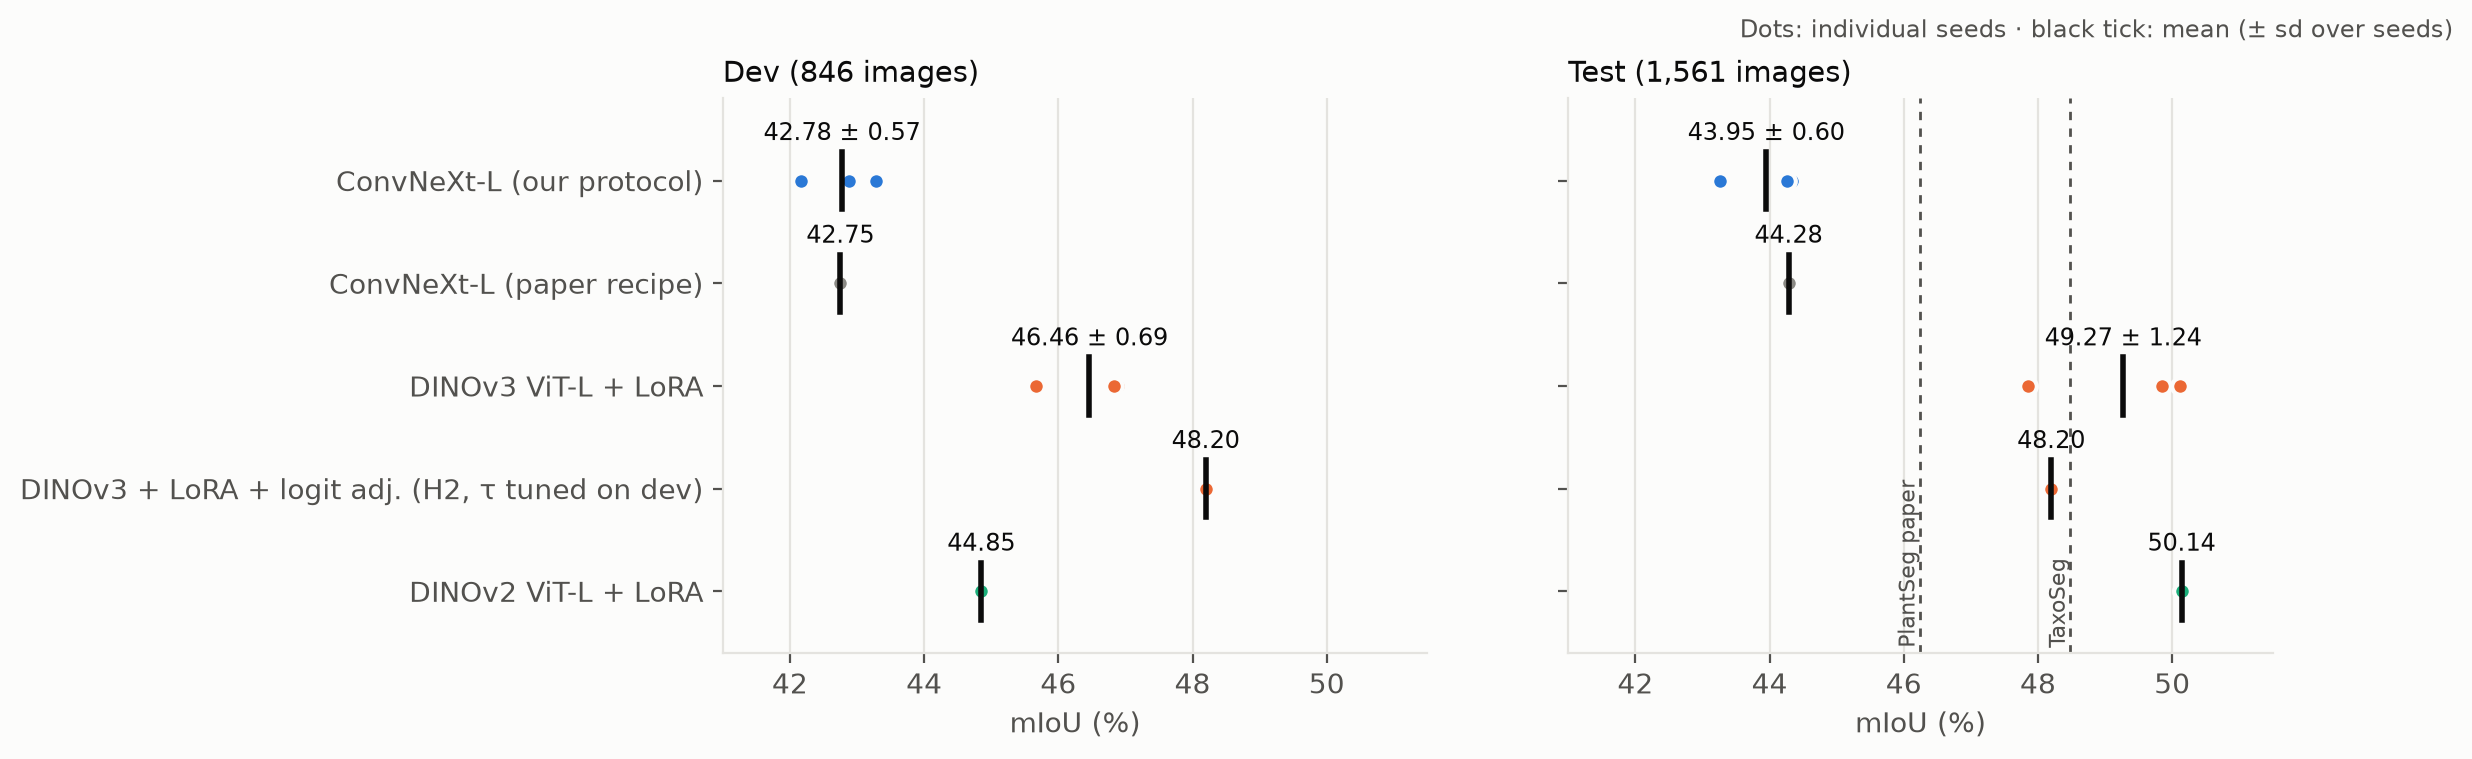

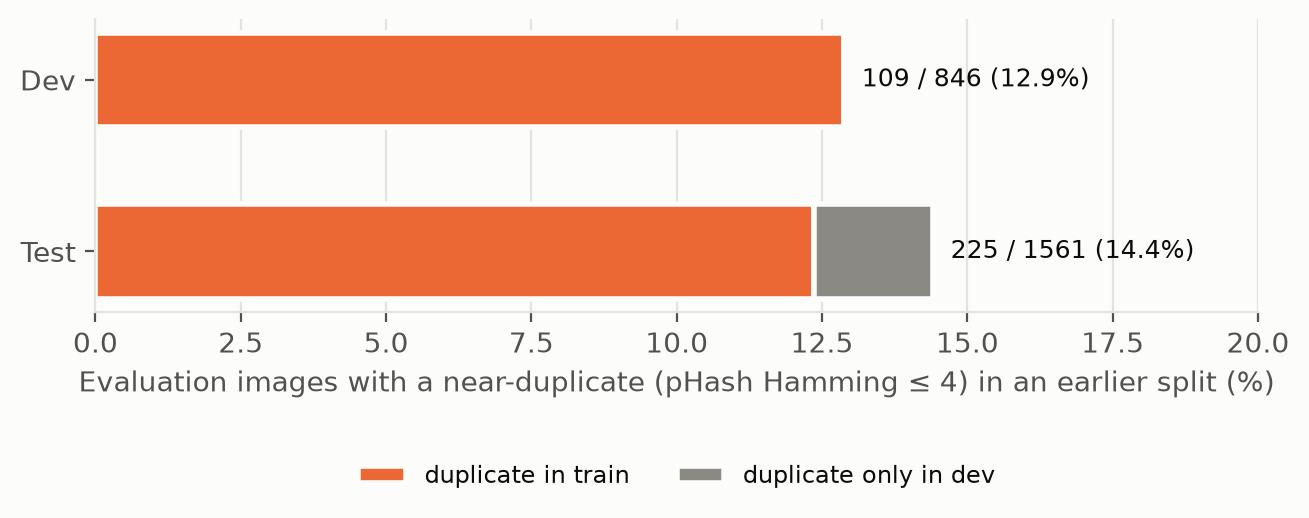

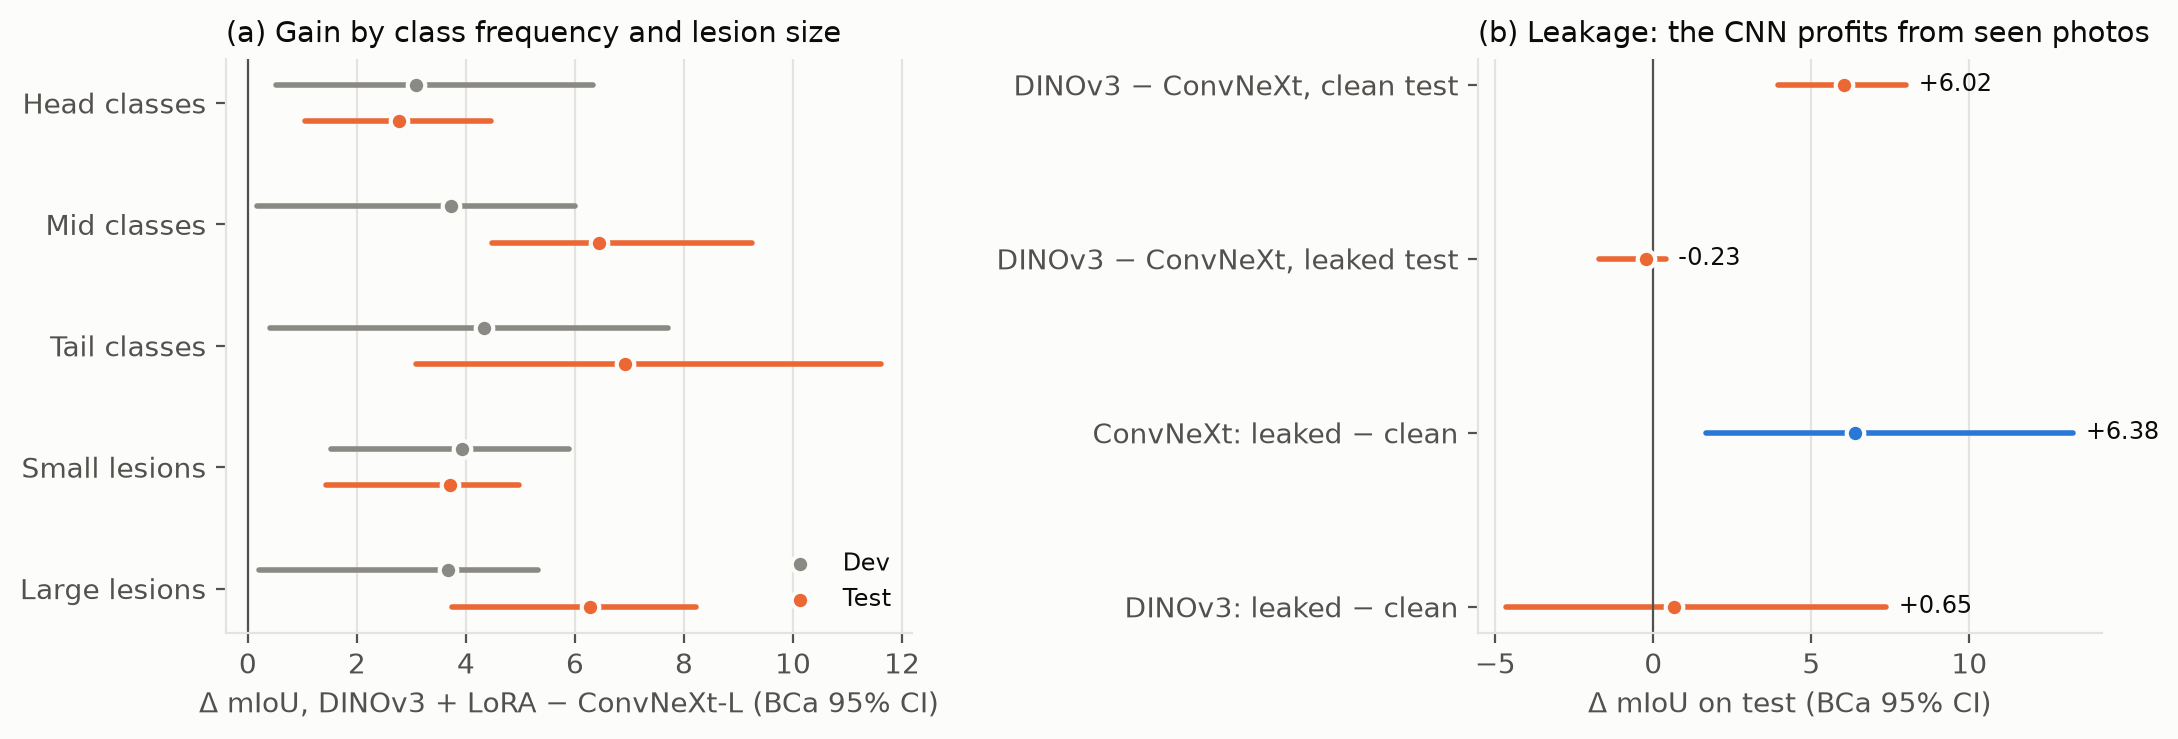

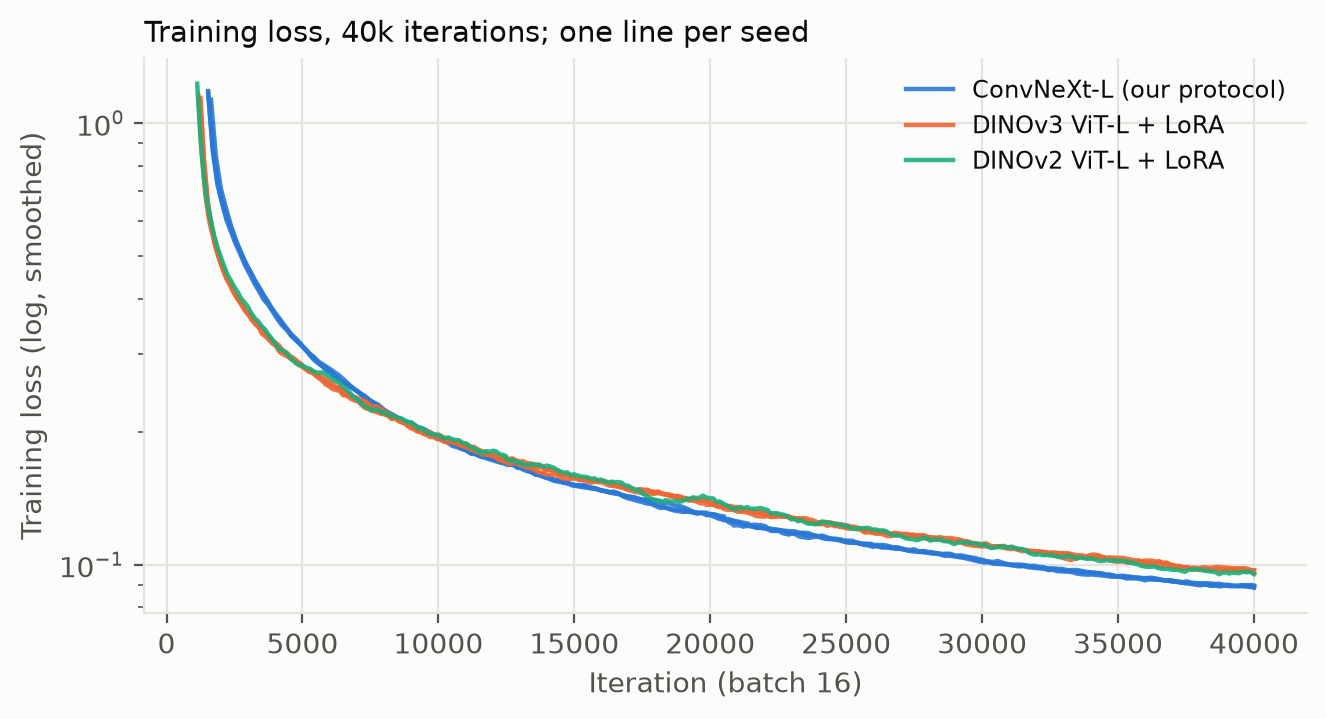

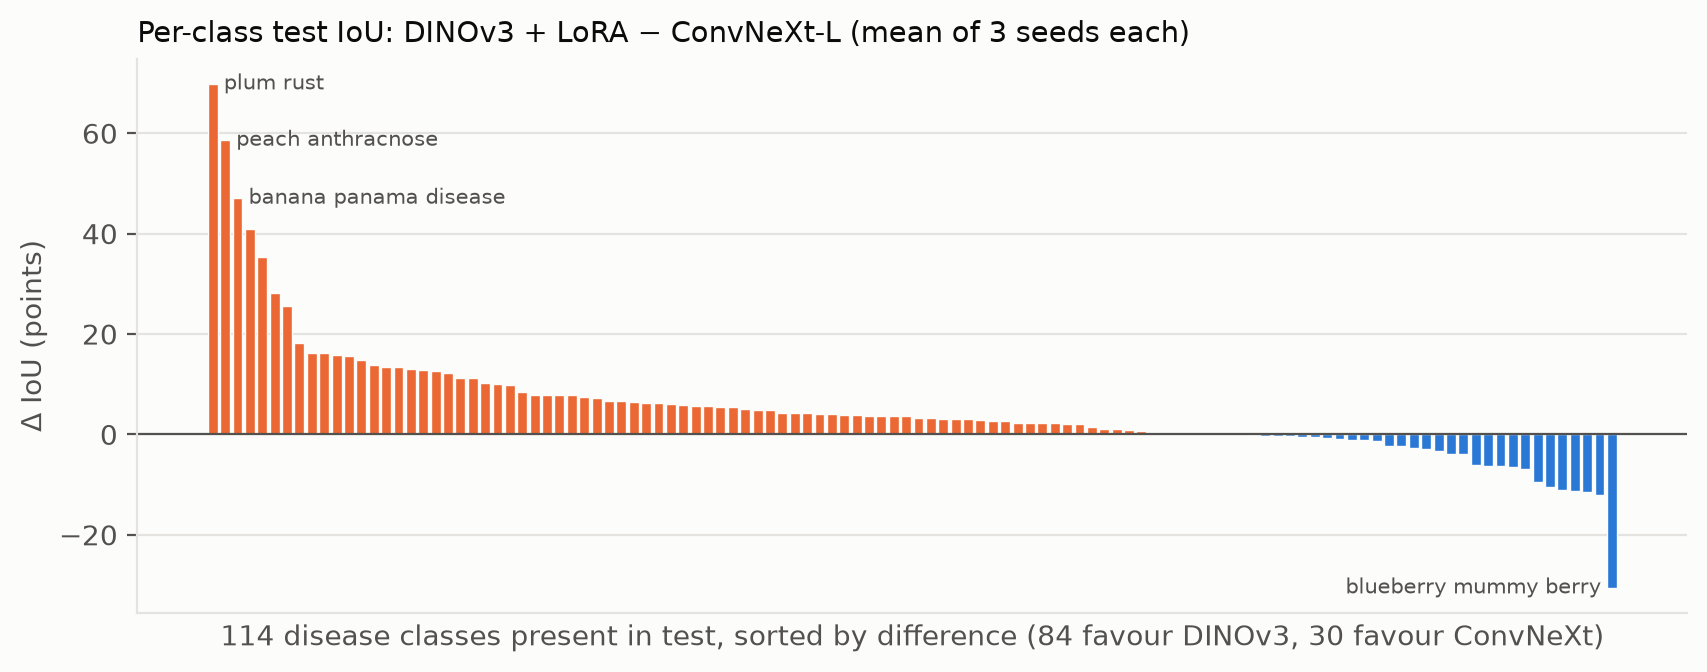

In [9]:
run(["analysis/figures.py"])
for f in ["fig1_main_results", "fig2_leakage_rate", "fig3_subgroups", "fig4_training_curves", "fig5_per_class_delta"]:
    display(Image(filename=str(R / "figures" / f"{f}.png"), width=900))